# Tracking Through a Simple Lattice

In this example, we create a custom lattice and track a beam through it. We start with some imports.


In [1]:
import matplotlib.pyplot as plt
import torch

import cheetah

Lattices in _Cheetah_ are represented by `Segments`. A `Segment` is created as follows.


In [2]:
segment = cheetah.Segment(
    elements=[
        cheetah.Drift(length=torch.tensor(0.175)),
        cheetah.Quadrupole(length=torch.tensor(0.122), name="AREAMQZM1"),
        cheetah.Drift(length=torch.tensor(0.428)),
        cheetah.Quadrupole(length=torch.tensor(0.122), name="AREAMQZM2"),
        cheetah.Drift(length=torch.tensor(0.204)),
        cheetah.VerticalCorrector(length=torch.tensor(0.02), name="AREAMCVM1"),
        cheetah.Drift(length=torch.tensor(0.204)),
        cheetah.Quadrupole(length=torch.tensor(0.122), name="AREAMQZM3"),
        cheetah.Drift(length=torch.tensor(0.179)),
        cheetah.HorizontalCorrector(length=torch.tensor(0.02), name="AREAMCHM1"),
        cheetah.Drift(length=torch.tensor(0.45)),
        cheetah.Screen(name="AREABSCR1"),
    ]
)

Alternatively you can load lattices from Cheetah's variant of LatticeJSON or convert them from an Ocelot cell

```python
lattice_json_segment = cheetah.Segment.from_lattice_json("lattice_file.json")
segment = cheetah.Segment.from_ocelot(cell)
```


> **Common Pitfalls & PyTorch Best Practices:**
>
> - **Parameters must be `torch.Tensor`s**: Element lengths, angles, and magnet strengths (`k1`, `voltage`, etc.) must always be passed as `torch.tensor(...)`. Passing raw Python `float`s will raise an error because Cheetah uses automatic differentiation.
> - **Device & Dtype Consistency**: PyTorch requires all interacting elements and beams to share the same `device` (`"cpu"`, `"cuda"`, or `"mps"`) and data type (`torch.float32` or `torch.float64`). You can migrate an entire `Segment` or `Beam` simultaneously using `.to(device=..., dtype=...)`.
> - **Named Element Access**: Elements assigned a `name` during instantiation can be accessed directly as attributes of the `Segment` to inspect or update their parameters dynamically:


In [3]:
segment.AREAMQZM1.k1 = torch.tensor(8.2)
segment.AREAMQZM2.k1 = torch.tensor(-14.3)
segment.AREAMCVM1.angle = torch.tensor(9e-5)
segment.AREAMQZM3.k1 = torch.tensor(3.142)
segment.AREAMCHM1.angle = torch.tensor(-1e-4)

### Slicing and Manipulating Lattices

Real-world workflows often require isolating sub-beamlines or tracking up to a specific element:

- **Extracting a subcell**: `segment.subcell(start="AREAMQZM1", end="AREAMQZM3")` extracts elements between two points. Set `include_start` or `include_end` to `False` to omit endpoints.
- **Partitioning**: `segment.partition_at("AREABSCR1", mode="both")` splits a segment into three parts: elements before the element, the element itself, and elements after.
- **Lattice reversal**: `segment.reversed()` reverses element order and inverts directional angles for backwards tracking or reflecting symmetric beamlines.
- **Lattice flattening & pruning**: `segment.flattened()` unpacks nested subsegments into a flat list, and `segment.without_inactive_markers()` removes zero-length diagnostic markers to eliminate tracking overhead.


In [ ]:
# Extract a subcell between the first two quadrupoles
sub_lattice = segment.subcell(start="AREAMQZM1", end="AREAMQZM2")
print("Subcell elements:", [el.name for el in sub_lattice.elements])

# Partition around the screen
pre_screen, screen, post_screen = segment.partition_at("AREABSCR1", mode="both")
print(f"Elements before screen: {len(pre_screen.elements)}, after: {len(post_screen.elements)}")


Cheetah has two different beam classes: `ParticleBeam` and `ParameterBeam`. The former tracks multiple individual macroparticles for high-fidelity results, while the latter tracks the parameters of a particle distribution to save on compute time and memory.

You can create a beam manually by specifying the beam parameters of a Gaussian distributed beam


In [4]:
parameter_beam = cheetah.ParameterBeam.from_twiss(beta_x=torch.tensor(3.14))
particle_beam = cheetah.ParticleBeam.from_twiss(
    beta_x=torch.tensor(3.14), beta_y=torch.tensor(42.0), num_particles=10_000
)

or load beams from other codes and standards, including openPMD, Ocelot and Astra.


In [5]:
astra_beam = cheetah.ParticleBeam.from_astra(
    "../../tests/resources/ACHIP_EA1_2021.1351.001"
)

In order to track a beam through the segment, simply call the segment's `track` method.


In [6]:
outgoing_beam = segment.track(astra_beam)

You may plot a segment with reference particle traces by calling


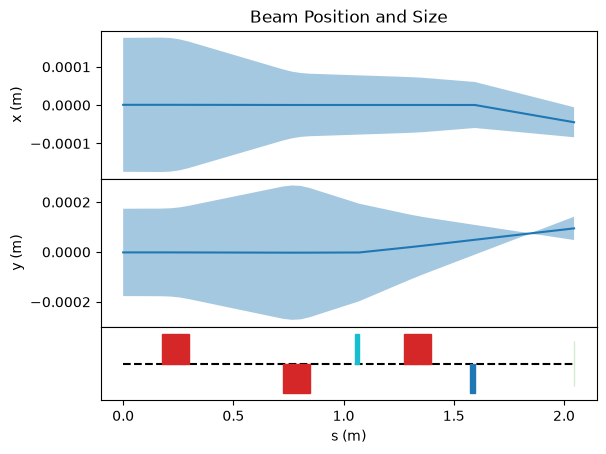

In [7]:
segment.plot_overview(incoming=astra_beam, resolution=0.05)
plt.show()

where the keyword argument `incoming` is the incoming beam represented by the reference particles.


You can also visualise your segment in 3D. **NOTE** that this requires that you installed Cheetah as `pip install cheetah-accelerator[3d-visualization]`.

Use `mesh.show` to view the mesh and `mesh.export` to export it to a file.


In [8]:
mesh, _ = segment.to_mesh(
    cuteness={cheetah.HorizontalCorrector: 2.0, cheetah.VerticalCorrector: 2.0}
)
mesh.show()

In [9]:
mesh.export(file_obj="my_first_cheetah_mesh.glb", file_type="glb")

b'glTF\x02\x00\x00\x00(\xedE\x00d\x17\x00\x00JSON{"scene":0,"scenes":[{"nodes":[0]}],"asset":{"version":"2.0","generator":"https://github.com/mikedh/trimesh"},"accessors":[{"componentType":5125,"type":"SCALAR","bufferView":0,"count":8016,"max":[1725],"min":[0]},{"componentType":5126,"type":"VEC3","byteOffset":0,"bufferView":1,"count":1726,"max":[0.13898545503616333,0.13898545503616333,0.2968865931034088],"min":[-0.13898545503616333,-0.13898545503616333,0.17488659918308258]},{"componentType":5126,"type":"VEC2","byteOffset":0,"bufferView":4,"count":1726,"max":[0.5597211122512817,0.6830357313156128],"min":[0.14895834028720856,0.6205357313156128]},{"componentType":5126,"type":"VEC3","byteOffset":0,"bufferView":5,"count":1726,"max":[0.13898545503616333,0.13898545503616333,0.8468865752220154],"min":[-0.13898545503616333,-0.13898545503616333,0.7248865962028503]},{"componentType":5125,"type":"SCALAR","bufferView":6,"count":23916,"max":[4415],"min":[0]},{"componentType":5126,"type":"VEC3","byte